In [2]:
import numpy as np
import matplotlib.pyplot as plt

import helpers
from compression import zstd

In [3]:
x_train, x_test, y_train, train_ids, test_ids = helpers.load_data("../data")

In [4]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)

(328135, 321)
(109379, 321)
(328135,)


## Exploratory Data Analysis

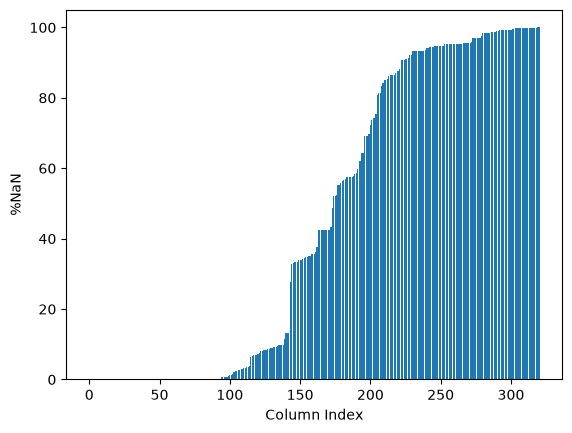

In [5]:
nan_frac = np.sort(np.mean(np.isnan(x_train), axis=0))

plt.bar(np.arange(x_train.shape[1]), nan_frac*100)
plt.xlabel("Column Index")
plt.ylabel("%NaN")
plt.show()

A lot of columns are majority NaN. We should pich a threshold to drop these columns.<br/>

In [6]:
with zstd.open("../data/x_train.csv.zst", "rt") as f:
    header = f.readline()
col_names = np.array(header.strip().split(",")[1:])
idx = {name: j for j, name in enumerate(col_names)}


In [7]:
nan_frac = np.isnan(x_train).mean(axis=0)
n_unique = np.array([len(np.unique(c[~np.isnan(c)])) for c in x_train.T])

def summary(j):
    c = x_train[:, j]; c = c[~np.isnan(c)]
    vals, counts = np.unique(c, return_counts=True)
    top = vals[np.argsort(counts)[::-1][:5]]
    return f"{col_names[j]:<10} nan={nan_frac[j]:.0%} uniq={n_unique[j]:<5} min={c.min():g} max={c.max():g} top={top}"

for j in np.argsort(nan_frac):
    print(summary(j))


_STATE     nan=0% uniq=53    min=1 max=72 top=[20. 31. 27. 53. 48.]
PERSDOC2   nan=0% uniq=5     min=1 max=9 top=[1. 3. 2. 7. 9.]
HLTHPLN1   nan=0% uniq=4     min=1 max=9 top=[1. 2. 7. 9.]
MENTHLTH   nan=0% uniq=33    min=1 max=99 top=[88. 30.  2.  5.  1.]
BLOODCHO   nan=0% uniq=4     min=1 max=9 top=[1. 2. 7. 9.]
CHCOCNCR   nan=0% uniq=4     min=1 max=9 top=[2. 1. 7. 9.]
ASTHMA3    nan=0% uniq=4     min=1 max=9 top=[2. 1. 7. 9.]
PAMISS1_   nan=0% uniq=3     min=0 max=9 top=[0. 9. 1.]
CVDSTRK3   nan=0% uniq=4     min=1 max=9 top=[2. 1. 7. 9.]
EMPLOY1    nan=0% uniq=9     min=1 max=9 top=[1. 7. 2. 8. 5.]
MARITAL    nan=0% uniq=7     min=1 max=9 top=[1. 5. 2. 3. 6.]
EDUCA      nan=0% uniq=7     min=1 max=9 top=[6. 4. 5. 3. 2.]
SEX        nan=0% uniq=2     min=1 max=2 top=[2. 1.]
CHCKIDNY   nan=0% uniq=4     min=1 max=9 top=[2. 1. 7. 9.]
ADDEPEV2   nan=0% uniq=4     min=1 max=9 top=[2. 1. 7. 9.]
CHCCOPD1   nan=0% uniq=4     min=1 max=9 top=[2. 1. 7. 9.]
RENTHOM1   nan=0% uniq=5     min=1 

## Relationship with the label
**Question:** does knowing someone's answer to a question change how likely they are to have MICHD?

Overall, ~8.8% of respondents are positive (the *baseline*). For each categorical column (2 to 10 distinct values), we split the rows by their answer and compute the positive rate in each group. For example, for `CVDSTRK3` (*ever had a stroke?*), people who answered *yes* are positive far more often than 8.8%, while those who answered *no* are slightly below it. A column like the interview month gives ~8.8% in every group, so it carries no signal.

We measure this with [Cramér's V](https://en.wikipedia.org/wiki/Cram%C3%A9r%27s_V), the effect size of [Pearson's chi-squared test of independence](https://en.wikipedia.org/wiki/Pearson%27s_chi-squared_test) between the column and the label. With a binary label, the chi-squared statistic simplifies to
$$\chi^2 = \sum_v \frac{n_v\,(r_v - p)^2}{p(1-p)}, \qquad V = \sqrt{\chi^2 / N}$$
where $n_v$ is the number of rows with value $v$, $r_v$ their positive rate, $p$ the positive rate over the $N$ non-missing rows. $V = 0$ means the column is independent of the label, $V = 1$ means it determines it. For a binary label, $V$ equals the [correlation ratio](https://en.wikipedia.org/wiki/Correlation_ratio) $\eta$.

We report $V$ rather than the test's p-value: with ~300k rows almost every column is "significant", so the p-value doesn't help rank them.

Notes:
- Deviations in both directions count, so $V$ shows how strongly a column separates people, not which answer is risky (read the per-value rates for that).
- This measures association, not causation (a stroke doesn't cause heart attacks, but they share risk factors).
- NaN rows are ignored here; missingness is analysed separately below.
- Columns with < 20% non-missing rows are skipped, since their rates come from a small subgroup.
- Output format: `value:rate(count in thousands)`.

In [15]:
pos = y_train == 1
print(f"base rate: {pos.mean():.3f}")

rows = []
for j in np.where((n_unique > 1) & (n_unique <= 10) & (nan_frac < 0.8))[0]:
    c = x_train[:, j]
    ok = ~np.isnan(c)
    p = pos[ok].mean()
    if not 0 < p < 1:
        continue
    vals, inv, counts = np.unique(c[ok], return_inverse=True, return_counts=True)
    rates = np.bincount(inv, weights=pos[ok]) / counts
    chi2 = np.sum(counts * (rates - p) ** 2) / (p * (1 - p))
    v = np.sqrt(chi2 / ok.sum())  # Cramer's V
    rows.append((v, j, vals, rates, counts))

for v, j, vals, rates, counts in sorted(rows, key=lambda r: -r[0])[:20]:
    desc = " ".join(f"{val:g}:{r:.2f}({n // 1000}k)" for val, r, n in zip(vals, rates, counts))
    print(f"{col_names[j]:<10} V={v:.3f} nan={nan_frac[j]:.0%}  {desc}")


base rate: 0.088
GENHLTH    V=0.266 nan=0%  1:0.02(56k) 2:0.04(108k) 3:0.09(101k) 4:0.19(43k) 5:0.32(16k) 7:0.17(0k) 9:0.14(0k)
_RFHLTH    V=0.235 nan=0%  1:0.06(266k) 2:0.23(60k) 9:0.16(0k)
EMPLOY1    V=0.231 nan=0%  1:0.03(133k) 2:0.05(27k) 3:0.09(7k) 4:0.05(6k) 5:0.06(20k) 6:0.01(8k) 7:0.16(98k) 8:0.21(23k) 9:0.07(2k)
_AGE_G     V=0.222 nan=0%  1:0.01(18k) 2:0.01(31k) 3:0.02(37k) 4:0.05(53k) 5:0.09(73k) 6:0.17(113k)
BPHIGH4    V=0.218 nan=0%  1:0.16(131k) 2:0.03(2k) 3:0.04(189k) 4:0.06(3k) 7:0.15(0k) 9:0.04(0k)
_RFHYPE5   V=0.217 nan=0%  1:0.04(195k) 2:0.16(131k) 9:0.12(0k)
DIFFWALK   V=0.216 nan=3%  1:0.22(54k) 2:0.06(262k) 7:0.17(0k) 9:0.08(0k)
CVDSTRK3   V=0.209 nan=0%  1:0.37(13k) 2:0.08(314k) 7:0.32(0k) 9:0.25(0k)
_AGE65YR   V=0.203 nan=0%  1:0.05(211k) 2:0.17(112k) 3:0.06(3k)
_HCVU651   V=0.197 nan=0%  1:0.05(188k) 2:0.04(21k) 9:0.16(117k)
USEEQUIP   V=0.193 nan=2%  1:0.24(37k) 2:0.07(282k) 7:0.16(0k) 9:0.08(0k)
CHCCOPD1   V=0.189 nan=0%  1:0.27(26k) 2:0.07(300k) 7:0.24(1k) 9:

For continuous columns: standardized mean difference between classes, `d = (mean(y=1) - mean(y=-1)) / std`.

In [14]:
rows = []
for j in np.where((n_unique > 10) & (nan_frac < 0.8))[0]:
    c = x_train[:, j]
    ok = ~np.isnan(c)
    d = (c[ok & pos].mean() - c[ok & ~pos].mean()) / c[ok].std()
    rows.append((abs(d), j, d))

for _, j, d in sorted(rows, reverse=True)[:15]:
    print(f"{col_names[j]:<10} d={d:+.2f} nan={nan_frac[j]:.0%}")

_AGE80     d=+0.79 nan=0%
_AGEG5YR   d=+0.77 nan=0%
CHILDREN   d=+0.40 nan=0%
PHYSHLTH   d=-0.34 nan=0%
ALCDAY5    d=+0.31 nan=4%
PA1VIGM_   d=+0.24 nan=34%
STRENGTH   d=+0.23 nan=9%
NUMWOMEN   d=-0.22 nan=43%
DRNK3GE5   d=+0.21 nan=52%
PAVIG11_   d=+0.20 nan=35%
NUMADULT   d=-0.20 nan=42%
_BMI5      d=+0.19 nan=8%
WTKG3      d=+0.19 nan=7%
HIVTSTD3   d=+0.18 nan=74%
_PSU       d=-0.18 nan=0%


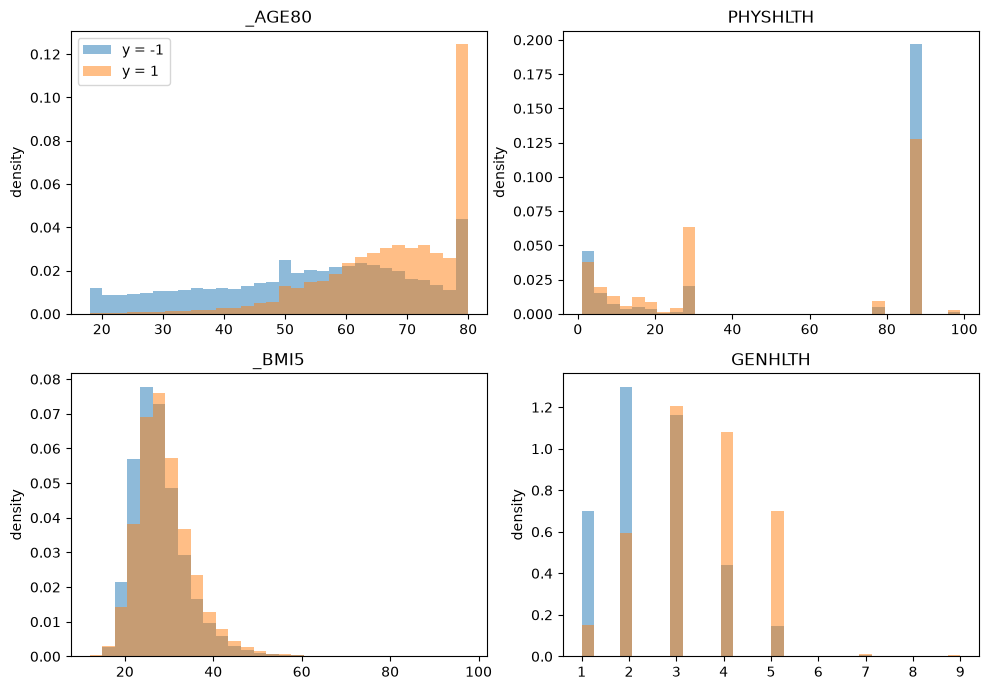

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, name in zip(axes.flat, ["_AGE80", "PHYSHLTH", "_BMI5", "GENHLTH"]):
    c = x_train[:, idx[name]]
    ok = ~np.isnan(c)
    bins = np.histogram_bin_edges(c[ok], bins=30)
    ax.hist(c[ok & ~pos], bins=bins, density=True, alpha=0.5, label="y = -1")
    ax.hist(c[ok & pos], bins=bins, density=True, alpha=0.5, label="y = 1")
    ax.set_title(name)
    ax.set_ylabel("density")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## Missingness as a signal
Many questions are only asked if a previous answer triggers them (e.g. the diabetes module is only asked to diabetics), so *whether* a column is missing can be informative on its own.

In [50]:
rows = []
for j in range(x_train.shape[1]):
    m = np.isnan(x_train[:, j])
    if 0 < m.sum() < len(m):
        rows.append((abs(pos[m].mean() - pos[~m].mean()), j, pos[m].mean(), pos[~m].mean(), (~m).sum()))

for _, j, p_nan, p_present, n in sorted(rows, reverse=True)[:15]:
    print(f"{col_names[j]:<10} present={n:<7} P(y=1|nan)={p_nan:.3f}  P(y=1|present)={p_present:.3f}")

HAREHAB1   present=773     P(y=1|nan)=0.086  P(y=1|present)=1.000
STREHAB1   present=517     P(y=1|nan)=0.088  P(y=1|present)=0.358
CDHELP     present=3084    P(y=1|nan)=0.086  P(y=1|present)=0.287
DIABAGE2   present=42220   P(y=1|nan)=0.069  P(y=1|present)=0.221
CDDISCUS   present=9620    P(y=1|nan)=0.084  P(y=1|present)=0.227
CDSOCIAL   present=9630    P(y=1|nan)=0.084  P(y=1|present)=0.227
CDASSIST   present=9646    P(y=1|nan)=0.084  P(y=1|present)=0.227
CDHOUSE    present=9658    P(y=1|nan)=0.084  P(y=1|present)=0.227
BLDSUGAR   present=21709   P(y=1|nan)=0.079  P(y=1|present)=0.219
DIABEDU    present=21705   P(y=1|nan)=0.079  P(y=1|present)=0.219
DIABEYE    present=21705   P(y=1|nan)=0.079  P(y=1|present)=0.219
INSULIN    present=21710   P(y=1|nan)=0.079  P(y=1|present)=0.219
EYEEXAM    present=21706   P(y=1|nan)=0.079  P(y=1|present)=0.219
CHKHEMO3   present=21706   P(y=1|nan)=0.079  P(y=1|present)=0.219
DOCTDIAB   present=21706   P(y=1|nan)=0.079  P(y=1|present)=0.219


`HAREHAB1` ("did you go to rehab after your heart attack?") is only asked to people who reported a heart attack, which is part of the label definition, so it leaks the label:

In [51]:
j = idx["HAREHAB1"]
present = ~np.isnan(x_train[:, j])
print("train rows with HAREHAB1:", present.sum(), " P(y=1 | present) =", pos[present].mean())
print("test rows with HAREHAB1: ", (~np.isnan(x_test[:, j])).sum())

train rows with HAREHAB1: 773  P(y=1 | present) = 1.0
test rows with HAREHAB1:  238


## Redundancy
Correlation between columns with < 20% NaN (NaNs mean-imputed). BRFSS has many calculated variables (prefixed `_`) that duplicate raw ones.

In [ ]:
keep = np.where((nan_frac < 0.2) & (n_unique > 1))[0]
Z = x_train[:, keep]
Z = np.where(np.isnan(Z), np.nanmean(Z, axis=0), Z)
Z = (Z - Z.mean(axis=0)) / Z.std(axis=0)
corr = Z.T @ Z / len(Z)

iu = np.triu_indices(len(keep), k=1)
pairs = sorted(zip(np.abs(corr[iu]), corr[iu], keep[iu[0]], keep[iu[1]]), reverse=True)
for _, r, a, b in pairs:
    if abs(r) < 0.95:
        break
    print(f"{col_names[a]:<10} {col_names[b]:<10} r={r:+.3f}")

## Train/test consistency

In [1]:
nan_test = np.isnan(x_test).mean(axis=0)
print("max |nan_frac train - test|:", np.abs(nan_test - nan_frac).max())

mean_diff = (np.nanmean(x_test, axis=0) - np.nanmean(x_train, axis=0)) / (np.nanstd(x_train, axis=0) + 1e-12)
for j in np.argsort(-np.abs(mean_diff))[:5]:
    print(f"{col_names[j]:<10} standardized mean diff={mean_diff[j]:+.3g}  nan={nan_frac[j]:.0%}")

NameError: name 'np' is not defined

## Univariate predictive power of every feature
To compare all 321 columns on the same scale, each column is encoded by the positive rate of its value (NaN counts as its own value, columns with > 20 unique values are first binned into 20 quantiles), and we compute the AUC of that encoding. AUC = 0.5 means no signal, 1.0 means perfect separation.

Binning matters: without it, near-unique columns such as `_LLCPWT` (survey weight) or `SEQNO` get a fake AUC close to 1, since every value has its own positive rate.

In [ ]:
def auc(score, y):
    # Mann-Whitney U statistic, ties get their average rank
    order = np.argsort(score, kind="mergesort")
    _, first, counts = np.unique(score[order], return_index=True, return_counts=True)
    ranks = np.empty(len(score))
    ranks[order] = np.repeat(first + (counts + 1) / 2, counts)
    n1 = y.sum()
    n0 = len(y) - n1
    return (ranks[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def encode_rate(c, y, n_bins=20):
    c = c.copy()
    nan = np.isnan(c)
    if np.unique(c[~nan]).size > n_bins:
        edges = np.unique(np.quantile(c[~nan], np.linspace(0, 1, n_bins + 1)[1:-1]))
        c[~nan] = np.searchsorted(edges, c[~nan])
    c[nan] = -1
    _, inv = np.unique(c, return_inverse=True)
    rate = np.bincount(inv, weights=y) / np.bincount(inv)
    return rate[inv]


aucs = np.array([
    auc(encode_rate(x_train[:, j], pos), pos) if n_unique[j] > 0 else 0.5
    for j in range(x_train.shape[1])
])
print(f"AUC > 0.60: {(aucs > 0.6).sum()} features")
print(f"AUC > 0.55: {(aucs > 0.55).sum()} features")
print(f"AUC < 0.52: {(aucs < 0.52).sum()} features (almost no signal)")

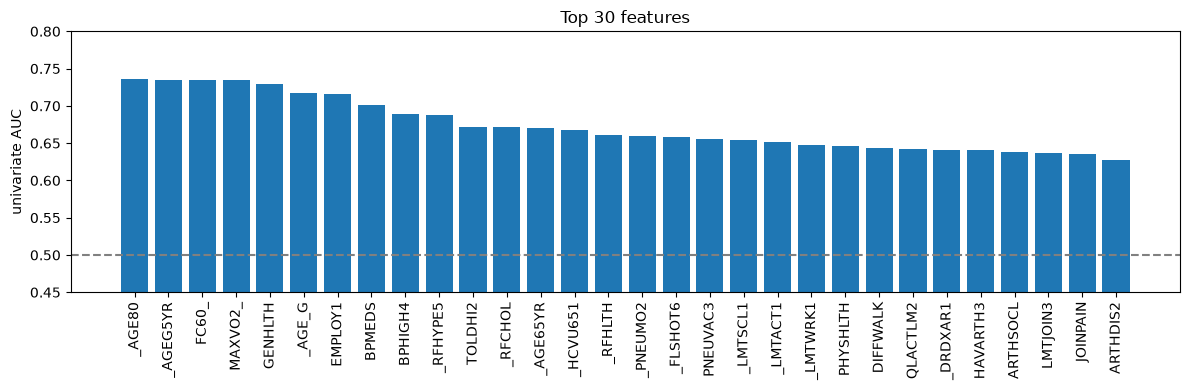

In [55]:
top = np.argsort(-aucs)[:30]
plt.figure(figsize=(12, 4))
plt.bar(col_names[top], aucs[top])
plt.axhline(0.5, color="gray", linestyle="--")
plt.ylim(0.45, 0.8)
plt.xticks(rotation=90)
plt.ylabel("univariate AUC")
plt.title("Top 30 features")
plt.tight_layout()
plt.show()

## Survey modules
Columns that share exactly the same missingness pattern belong to the same block of questions (asked or skipped together). One missing indicator per block is enough, though exact sharing turns out to be limited.

In [56]:
masks = np.isnan(x_train)
blocks = {}
for j in range(x_train.shape[1]):
    if 0 < nan_frac[j] < 1:
        blocks.setdefault(masks[:, j].tobytes(), []).append(j)

print(f"{sum(map(len, blocks.values()))} partially missing columns, {len(blocks)} distinct missingness patterns")
for cols in sorted(blocks.values(), key=len, reverse=True)[:8]:
    present = ~masks[:, cols[0]]
    print(f"{len(cols)} cols  nan={1 - present.mean():.0%}  P(y=1|present)={pos[present].mean():.3f}  {list(col_names[cols])}")

239 partially missing columns, 214 distinct missingness patterns
5 cols  nan=42%  P(y=1|present)=0.107  [np.str_('CTELENUM'), np.str_('PVTRESD1'), np.str_('CELLFON3'), np.str_('NUMHHOL2'), np.str_('CPDEMO1')]
4 cols  nan=1%  P(y=1|present)=0.088  [np.str_('_DRDXAR1'), np.str_('_LMTACT1'), np.str_('_LMTWRK1'), np.str_('_LMTSCL1')]
3 cols  nan=58%  P(y=1|present)=0.062  [np.str_('CTELNUM1'), np.str_('CELLFON2'), np.str_('PVTRESD2')]
3 cols  nan=13%  P(y=1|present)=0.098  [np.str_('CHOLCHK'), np.str_('TOLDHI2'), np.str_('_RFCHOL')]
2 cols  nan=100%  P(y=1|present)=0.156  [np.str_('COLGHOUS'), np.str_('LADULT')]
2 cols  nan=0%  P(y=1|present)=0.088  [np.str_('MEDCOST'), np.str_('CHECKUP1')]
2 cols  nan=10%  P(y=1|present)=0.089  [np.str_('HIVTST6'), np.str_('_AIDTST3')]
2 cols  nan=93%  P(y=1|present)=0.219  [np.str_('CHKHEMO3'), np.str_('EYEEXAM')]


## Raw vs calculated variables
The CDC provides calculated versions of many raw answers (e.g. `DROCDY3_` = drinks per day, computed from `ALCDAY5` which mixes `1xx` = days/week and `2xx` = days/month). They carry the same signal but in usable units, so prefer them over re-implementing the conversions. `WEIGHT2` additionally mixes pounds and kilograms (`9xxx` = kg).

In [57]:
for raw, calc in [("ALCDAY5", "DROCDY3_"), ("FRUIT1", "FRUTDA1_"), ("STRENGTH", "STRFREQ_"),
                  ("WEIGHT2", "WTKG3"), ("HEIGHT3", "HTM4")]:
    print(f"{raw:<9} AUC={aucs[idx[raw]]:.3f}   {calc:<9} AUC={aucs[idx[calc]]:.3f}")

w = x_train[:, idx["WEIGHT2"]]
print("WEIGHT2 rows coded in kg (9000-9998):", ((w >= 9000) & (w < 9999)).sum())

ALCDAY5   AUC=0.589   DROCDY3_  AUC=0.588
FRUIT1    AUC=0.541   FRUTDA1_  AUC=0.546
STRENGTH  AUC=0.561   STRFREQ_  AUC=0.563
WEIGHT2   AUC=0.567   WTKG3     AUC=0.568
HEIGHT3   AUC=0.545   HTM4      AUC=0.544
WEIGHT2 rows coded in kg (9000-9998): 677


## Engineered feature: number of conditions
Count of yes answers (`= 1`) to stroke, high blood pressure, high cholesterol, diabetes, kidney disease, COPD, arthritis and difficulty walking.

In [ ]:
CONDITIONS = ["CVDSTRK3", "BPHIGH4", "TOLDHI2", "DIABETE3", "CHCKIDNY", "CHCCOPD1", "HAVARTH3", "DIFFWALK"]
n_cond = sum((x_train[:, idx[name]] == 1) for name in CONDITIONS).astype(float)

vals, inv, counts = np.unique(n_cond, return_inverse=True, return_counts=True)
rates = np.bincount(inv, weights=pos) / counts
for v, r, n in zip(vals, rates, counts):
    print(f"{v:.0f} conditions: P(y=1) = {r:.3f}  ({n} rows)")
print(f"AUC of the count alone: {auc(n_cond, pos):.3f}  (best single raw feature: {aucs.max():.3f})")

plt.bar(vals, rates * 100)
plt.xlabel("number of conditions")
plt.ylabel("% with MICHD")
plt.show()

## Interaction: sex × age

In [ ]:
sex = x_train[:, idx["SEX"]]
age = x_train[:, idx["_AGEG5YR"]]  # 13 five-year groups, 18-24 ... 80+
ages = np.arange(1, 14)
for s, label in [(1, "male"), (2, "female")]:
    plt.plot(ages, [pos[(sex == s) & (age == a)].mean() * 100 for a in ages], marker="o", label=label)
plt.xticks(ages, ["18", "25", "30", "35", "40", "45", "50", "55", "60", "65", "70", "75", "80+"])
plt.xlabel("age group")
plt.ylabel("% with MICHD")
plt.legend()
plt.show()

## State

In [60]:
state = x_train[:, idx["_STATE"]]
vals, inv, counts = np.unique(state, return_inverse=True, return_counts=True)
rates = np.bincount(inv, weights=pos) / counts
print(f"{len(vals)} states, positive rate from {rates.min():.3f} to {rates.max():.3f}, AUC={aucs[idx['_STATE']]:.3f}")

53 states, positive rate from 0.053 to 0.141, AUC=0.542
